In [12]:
#Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

In [13]:
#Load Dataset
df = pd.read_csv("employee_salary_dataset.csv")
df.head()

,Years_Experience,Education_Level,Skill_Count,Skill_Level,Company_Type,Salary_LPA
0,1,UG,2,Intermediate,Mid_Size,7.75
1,3,Diploma,7,Advanced,Product_Based,11.25
2,10,UG,1,Beginner,Service_Based,13.00
3,10,PG,6,Advanced,Service_Based,17.00
4,5,Diploma,7,Beginner,Product_Based,10.25


In [14]:
#Data Preprocessing
df['Education_Level'] = df['Education_Level'].map({
    'Diploma':1,
    'UG':2,
    'PG':3
})

df['Skill_Level'] = df['Skill_Level'].map({
    'Beginner':1,
    'Intermediate':2,
    'Advanced':3
})

In [15]:
# Feature Engineering
df['Skill_Score'] = df['Skill_Count'] * df['Skill_Level']

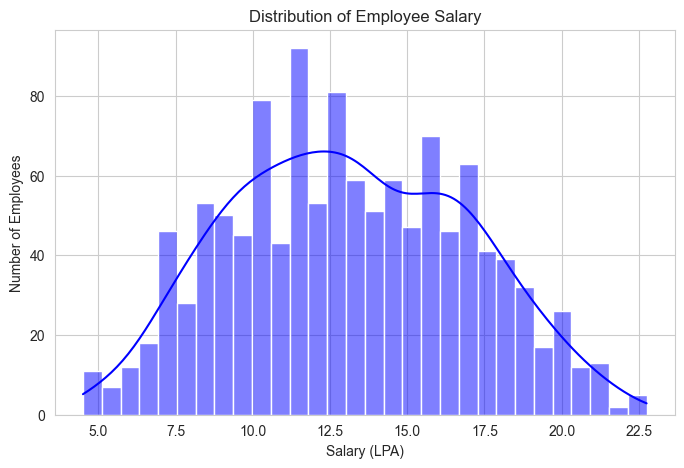

In [16]:
#Exploratory Data Analysis
#5.1: Salary Distribution
plt.figure()
sns.histplot(df['Salary_LPA'],bins=30,kde=True,color='blue')
plt.title("Distribution of Employee Salary")
plt.xlabel("Salary (LPA)")
plt.ylabel("Number of Employees")
plt.show()

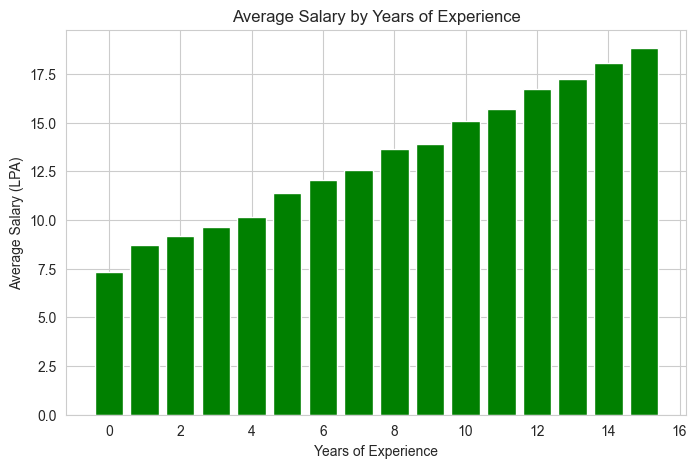

In [17]:
#5.2: Experience vs Salary
avg_salary_exp = df.groupby('Years_Experience')['Salary_LPA'].mean()
plt.figure()
plt.bar(avg_salary_exp.index,avg_salary_exp.values,color='green')
plt.title("Average Salary by Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Average Salary (LPA)")
plt.show()

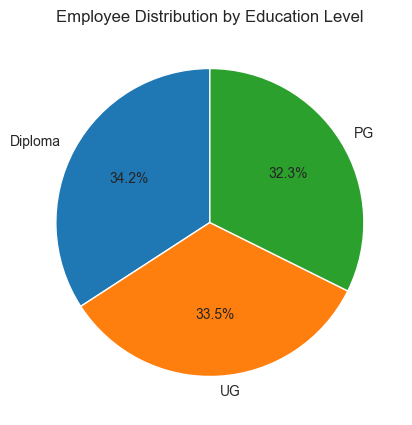

In [18]:
#5.3 Education Level vs Salary
edu_counts = df['Education_Level'].value_counts()
labels = ['Diploma','UG','PG']
plt.figure()
plt.pie(edu_counts,labels=labels,autopct='%1.1f%%',startangle=90)
plt.title("Employee Distribution by Education Level")
plt.show()

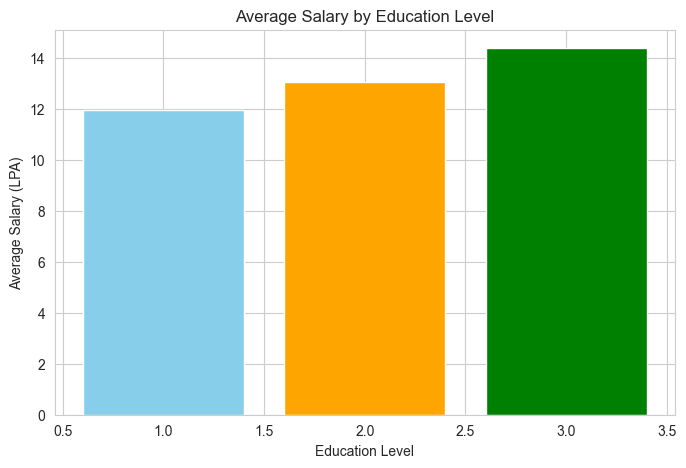

In [19]:
#5.4 Average Salary by Education
avg_salary = df.groupby('Education_Level')['Salary_LPA'].mean()
plt.figure()
plt.bar(avg_salary.index,avg_salary.values, color=['skyblue','orange','green'])
plt.title("Average Salary by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Average Salary (LPA)")
plt.show()

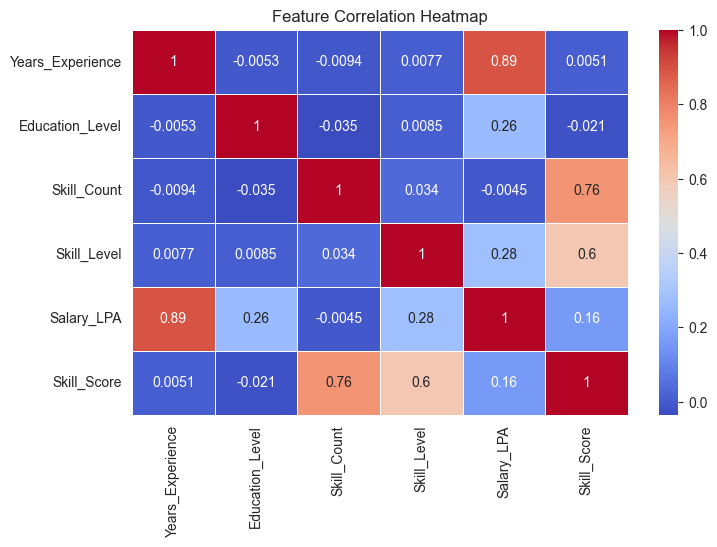

In [20]:
#5.5 Correlation Heatmap
plt.figure()
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm',linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

In [21]:
#Feature Selection
X = df[['Years_Experience','Education_Level','Skill_Score']]
y = df['Salary_LPA']

In [22]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
#Train Random Forest Model
model = RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [24]:
#Model Prediction
y_pred = model.predict(X_test)

In [25]:
#Model Evaluation
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Absolute Error:", round(mae,2))
print("R2 Score:", round(r2,2))

Mean Absolute Error: 1.07
R2 Score: 0.88


C:\Users\win10\AppData\Local\Temp\ipykernel_4088\273796759.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance,y=features,palette="viridis")


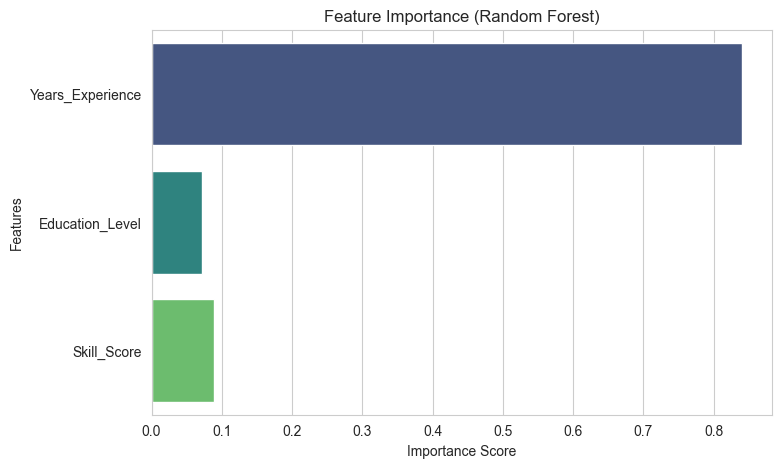

In [26]:
#Feature Importance Visualization
importance = model.feature_importances_
features = X.columns
plt.figure()
sns.barplot(x=importance,y=features,palette="viridis")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

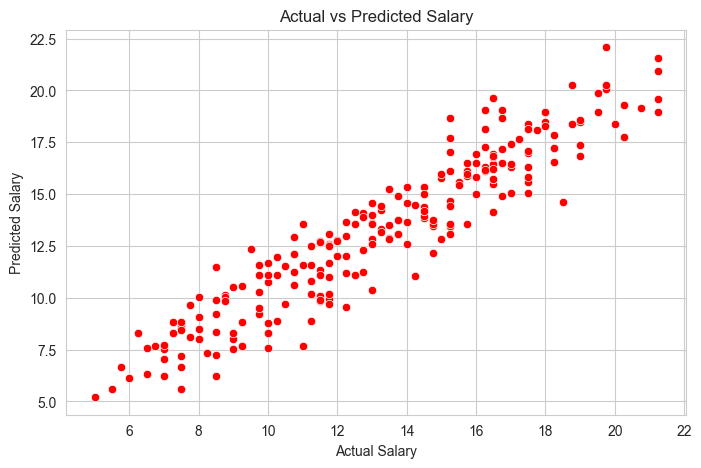

In [27]:
#Predicted vs Actual Salary
plt.figure()
sns.scatterplot(x=y_test,y=y_pred,color='red')
plt.title("Actual vs Predicted Salary")
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.show()

In [28]:
#Convert Salary into Categories
def categorize_salary(salary):
    
    if salary < 5:
        return "Low"
    
    elif salary < 10:
        return "Medium"
    
    else:
        return "High"

df['Salary_Category'] = df['Salary_LPA'].apply(categorize_salary)
df['Salary_Category'] = df['Salary_Category'].map({
    'Low':0,
    'Medium':1,
    'High':2
})

In [29]:
#Train Decision Tree Classifier
X_class = df[['Years_Experience','Education_Level','Skill_Score']]
y_class = df['Salary_Category']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42
)

In [30]:
#Train Classification Model
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_c, y_train_c)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [31]:
##Prediction
y_pred_class = dt_model.predict(X_test_c)

In [32]:
#Test Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_c, y_pred_class)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9291666666666667


In [33]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_c, y_pred_class)

print(cm)

[[ 43  10]
 [  7 180]]


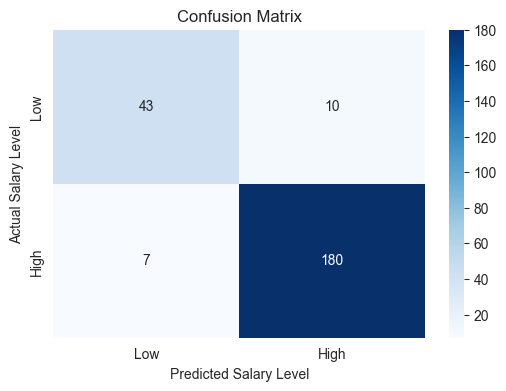

In [38]:
#Confusion Matrix Visualization
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low','High'],
    yticklabels=['Low','High']
)

plt.xlabel("Predicted Salary Level")
plt.ylabel("Actual Salary Level")

plt.title("Confusion Matrix")

plt.show()

In [35]:
#Salary Prediction Function
def predict_salary(exp, edu, skill_count, skill_level):

    edu_map = {'Diploma':1,'UG':2,'PG':3}
    skill_map = {'Beginner':1,'Intermediate':2,'Advanced':3}
    skill_score = skill_count * skill_map[skill_level]
    input_data = np.array([[exp, edu_map[edu], skill_score]])
    prediction = model.predict(input_data)
    return round(prediction[0],2)

In [36]:
salary = predict_salary(5,'UG',6,'Advanced')
print("Predicted Salary:", salary, "LPA")

Predicted Salary: 10.51 LPA


C:\Users\win10\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
